# 04. Trích xuất 36 đặc trưng 

- Cắt các cửa sổ trượt 60 giây (bước nhảy 10 giây) và trích xuất 36 đặc trưng sinh lý.
- Tập dữ liệu gồm **3.040 cửa sổ** (904 Stress ~29,7%, 2.136 Non-stress ~70,3%).
- Dữ liệu được tạo bởi script `scripts/extract_wesad_features.py`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', None)
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'ai/requirements.txt').is_file() and (p / 'backend').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Vui lòng mở notebook trong repository ASD-EASE')
sys.path.insert(0, str(ROOT / 'ai'))

FEAT_DIR = ROOT / 'ai/data/processed/wesad/features-v1'
report = json.loads((FEAT_DIR / 'report.json').read_text(encoding='utf-8'))
df = pd.read_csv(FEAT_DIR / 'dataset.csv')

print(f'Số lượng cửa sổ: {len(df)}, Số đặc trưng: {report["feature_count"]}')
print(f'Tỷ lệ Stress: {report["total_stress_windows"]} ({report["stress_prevalence"]*100:.1f}%), Non-stress: {report["total_non_stress_windows"]}')

Số lượng cửa sổ: 3040, Số đặc trưng: 36
Tỷ lệ Stress: 904 (29.7%), Non-stress: 2136


## 1. Danh mục 36 đặc trưng 

- **14 EDA:** Tonic mean/std, Phasic mean/auc, SCR peak count, SCR amplitude...
- **13 ACC:** Gia tốc chuẩn mean/std/energy, cường độ chuyển động, các trục x/y/z.
- **9 HR:** Nhịp tim mean/std/min/max/slope và các cờ kiểm định hợp lệ.

In [2]:
# Đọc và trích xuất danh mục đặc trưng trực tiếp từ DataFrame của dataset đã nạp
meta_cols = {'subject_id', 'window_start_ms', 'window_end_ms', 'source_label_code', 'label'}
feature_cols = [c for c in df.columns if c not in meta_cols]

# Hàm tự động phân loại nhóm đặc trưng từ tên cột
def categorize_feature(name):
    if name.startswith('eda_tonic'): return 'Thành phần Tonic (SCL)'
    elif name.startswith('eda_phasic'): return 'Thành phần Phasic (SCR)'
    elif name.startswith('eda_scr'): return 'Đỉnh xung phản xạ SCR'
    elif name.startswith('eda_'): return 'Thống kê da cơ bản'
    elif name.startswith('acc_norm'): return 'Động học vector gia tốc'
    elif name.startswith('acc_motion'): return 'Cường độ vận động'
    elif name.startswith(('acc_x', 'acc_y', 'acc_z')): return 'Không gian 3 trục gia tốc'
    elif name in ('hr_valid_count', 'hr_valid_ratio', 'hr_is_valid'): return 'Độ tin cậy & Độ phủ HR'
    elif name.startswith('hr_'): return 'Biến thiên nhịp tim (HRV/HR)'
    return 'Khác'

# Trích xuất động thông tin từng đặc trưng từ dataset thực tế
catalog_rows = []
for idx, col in enumerate(feature_cols, 1):
    sensor = 'EDA' if col.startswith('eda_') else ('HR' if col.startswith('hr_') else 'ACC')
    s = df[col]
    
    catalog_rows.append({
        'STT': idx,
        'Tên đặc trưng': col,
        'Cảm biến': sensor,
        'Nhóm phân tích': categorize_feature(col),
        'Kiểu dữ liệu': str(s.dtype),
        'Số mẫu hợp lệ': f"{s.notna().sum():,}/{len(df):,}",
        'Min': round(float(s.min()), 3),
        'Max': round(float(s.max()), 3),
        'Mean ± Std': f"{s.mean():.3f} ± {s.std():.3f}"
    })

df_catalog = pd.DataFrame(catalog_rows).set_index('STT')

print(f"BẢNG DANH MỤC {len(df_catalog)} ĐẶC TRƯNG ĐƯỢC ĐỌC ĐỘNG TỪ DATASET ({len(df):,} CỬA SỔ):")
pd.set_option('display.max_rows', 45)
display(df_catalog)

print("\n5 dòng dữ liệu mẫu trích xuất từ 3.040 cửa sổ WESAD:")
display(df[['subject_id', 'label', 'eda_mean', 'eda_scr_count', 'acc_motion_intensity', 'hr_mean', 'hr_valid_ratio']].head())

BẢNG DANH MỤC 36 ĐẶC TRƯNG ĐƯỢC ĐỌC ĐỘNG TỪ DATASET (3,040 CỬA SỔ):


,Tên đặc trưng,Cảm biến,Nhóm phân tích,Kiểu dữ liệu,Số mẫu hợp lệ,Min,Max,Mean ± Std
STT,,,,,,,,
1,eda_mean,EDA,Thống kê da cơ bản,float64,"3,040/3,040",0.093,15.630,1.957 ± 2.652
2,eda_std,EDA,Thống kê da cơ bản,float64,"3,040/3,040",0.001,1.348,0.062 ± 0.105
3,eda_min,EDA,Thống kê da cơ bản,float64,"3,040/3,040",0.075,14.670,1.820 ± 2.458
4,eda_max,EDA,Thống kê da cơ bản,float64,"3,040/3,040",0.101,15.921,2.102 ± 2.800
5,eda_ptp,EDA,Thống kê da cơ bản,float64,"3,040/3,040",0.006,4.589,0.282 ± 0.455
6,eda_slope,EDA,Thống kê da cơ bản,float64,"3,040/3,040",-0.022,0.075,-0.000 ± 0.005
7,eda_tonic_mean,EDA,Thành phần Tonic (SCL),float64,"3,040/3,040",0.091,15.304,1.917 ± 2.596
8,eda_tonic_std,EDA,Thành phần Tonic (SCL),float64,"3,040/3,040",0.007,1.382,0.171 ± 0.230
9,eda_phasic_mean,EDA,Thành phần Phasic (SCR),float64,"3,040/3,040",0.002,0.437,0.047 ± 0.066



5 dòng dữ liệu mẫu trích xuất từ 3.040 cửa sổ WESAD:


,subject_id,label,eda_mean,eda_scr_count,acc_motion_intensity,hr_mean,hr_valid_ratio
0,S2,0,1.261388,17.0,0.296354,81.623441,0.716667
1,S2,0,1.181817,15.0,0.291667,80.494018,0.750000
2,S2,0,1.112433,14.0,0.254167,76.689133,0.650000
3,S2,0,1.043299,11.0,0.154688,78.217265,0.683333
4,S2,0,0.969360,10.0,0.114583,75.992296,0.583333


## 2. Mức độ ảnh hưởng của từng đặc trưng 

Đánh giá mức độ quan trọng nhãn Stress của từng đặc trưng thông qua **Hệ số tương quan Pearson**:

$$r = \frac{\sum (X_i - \bar{X})(Y_i - \bar{Y})}{\sqrt{\sum (X_i - \bar{X})^2 \sum (Y_i - \bar{Y})^2}}$$

* **Trong đó:**
  * $X$: Giá trị đặc trưng sinh lý trích xuất trong cửa sổ 60 giây (EDA, HR, ACC).
  * $Y$: Nhãn trạng thái mục tiêu ($0$: Bình thường, $1$: Stress).
  * **Độ lớn $|r|$ ($0 \to 1$):** Đo lường mức độ quan trọng và năng lực phân tách nhãn khi huấn luyện mô hình AI. Đặc trưng có $|r|$ càng lớn thì khả năng phân biệt giữa Bình thường và Stress càng mạnh, đóng vai trò quyết định trong việc ra quyết định của mô hình. Ngược lại, $|r| \approx 0$ nghĩa là đặc trưng không có giá trị phân biệt.

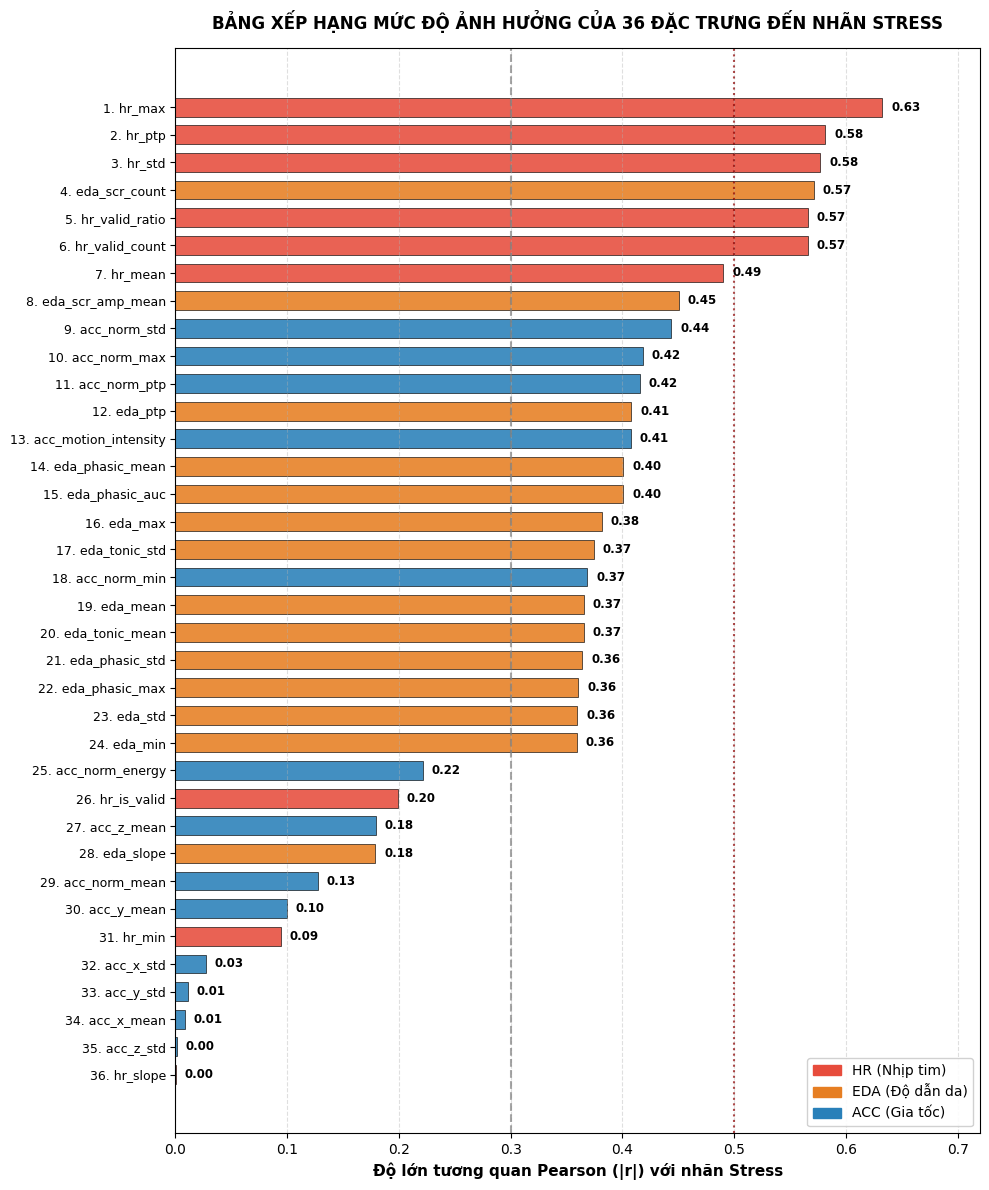

,Tên đặc trưng,Hệ số r,Độ lớn |r|,Cảm biến
Hạng,,,,
1,hr_max,0.632394,0.632394,HR
2,hr_ptp,0.581726,0.581726,HR
3,hr_std,0.576953,0.576953,HR
4,eda_scr_count,0.571174,0.571174,EDA
5,hr_valid_ratio,-0.565772,0.565772,HR
6,hr_valid_count,-0.565772,0.565772,HR
7,hr_mean,0.490325,0.490325,HR
8,eda_scr_amp_mean,0.450506,0.450506,EDA
9,acc_norm_std,0.443668,0.443668,ACC


In [3]:
# 1. Tính toán hệ số tương quan Pearson và sắp xếp theo độ lớn mức độ ảnh hưởng (|r|)
feature_names = report['feature_names']
corrs = df[feature_names].apply(lambda col: col.corr(df['label']))

df_rank = pd.DataFrame({
    'name': feature_names,
    'corr': [corrs[f] for f in feature_names],
    'abs_corr': [abs(corrs[f]) for f in feature_names]
}).sort_values(by='abs_corr', ascending=False).reset_index(drop=True)

# 2. Trực quan hóa Biểu đồ Cột ngang Xếp hạng Độ lớn |r| từ trên xuống dưới
fig, ax = plt.subplots(figsize=(10, 12))
y_pos = range(len(df_rank))

def get_sensor_color(name):
    if name.startswith('eda_'): return '#E67E22'  # Cam: EDA
    elif name.startswith('hr_'): return '#E74C3C'  # Đỏ: HR
    else: return '#2980B9'  # Xanh dương: ACC

colors = [get_sensor_color(n) for n in df_rank['name']]
bars = ax.barh(y_pos, df_rank['abs_corr'], color=colors, height=0.68, alpha=0.88, edgecolor='black', linewidth=0.5)

# Đặt nhãn hiển thị từ trên xuống dưới (Hạng 1 nằm ở đỉnh trên cùng)
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{i+1:2d}. {n}" for i, n in enumerate(df_rank['name'])], fontsize=9)
ax.invert_yaxis()

# Đường mốc tham chiếu các ngưỡng phân loại ảnh hưởng
ax.axvline(0.3, color='gray', linestyle='--', alpha=0.7, label='Ngưỡng vừa (|r| = 0.3)')
ax.axvline(0.5, color='darkred', linestyle=':', alpha=0.7, label='Ngưỡng mạnh (|r| = 0.5)')

# Ghi chú giá trị độ lớn |r| trên từng thanh
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.008, bar.get_y() + bar.get_height()/2, f"{w:.2f}",
            va='center', ha='left', fontsize=8.5, fontweight='bold')

ax.set_xlim(0, 0.72)
ax.set_xlabel('Độ lớn tương quan Pearson (|r|) với nhãn Stress', fontsize=11, fontweight='bold')
ax.set_title('BẢNG XẾP HẠNG MỨC ĐỘ ẢNH HƯỞNG CỦA 36 ĐẶC TRƯNG ĐẾN NHÃN STRESS', 
             fontsize=12, fontweight='bold', pad=14)
ax.grid(axis='x', linestyle='--', alpha=0.4)

import matplotlib.patches as mpatches
legend_patches = [
    mpatches.Patch(color='#E74C3C', label='HR (Nhịp tim)'),
    mpatches.Patch(color='#E67E22', label='EDA (Độ dẫn da)'),
    mpatches.Patch(color='#2980B9', label='ACC (Gia tốc)')
]
ax.legend(handles=legend_patches, loc='lower right', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()

# Hiển thị bảng Top 10 đặc trưng
top10_pearson = df_rank.head(10).copy()
top10_pearson['sensor'] = top10_pearson['name'].apply(lambda x: 'EDA' if x.startswith('eda_') else ('HR' if x.startswith('hr_') else 'ACC'))
top10_pearson.columns = ['Tên đặc trưng', 'Hệ số r', 'Độ lớn |r|', 'Cảm biến']
top10_pearson.index = range(1, 11)
top10_pearson.index.name = 'Hạng'
display(top10_pearson)